# NBA Player Value Analyzer
## Notebook 03: Exploratory Data Analysis

### Research Question
How closely does NBA player salary reflect on-court
performance during the 2024–25 regular season?

### Objectives
1. Examine the distribution of NBA player salaries.
2. Explore relationships between salary and performance.
3. Investigate scoring efficiency and salary.
4. Calculate correlations between key variables.
5. Identify interesting patterns to investigate in our
   player value model.

### Methodology
The primary analysis focuses on players with approximately
1,000 or more regular-season minutes and a matched salary.

This minimum playing-time requirement reduces the influence
of small sample sizes.

### Limitations
Salary figures are taken from a historical public dataset.
Salary definitions and historical team assignments require
additional validation before final player value rankings
are published.

This analysis identifies statistical associations,
not causal relationships.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

# Display options
pd.set_option("display.max_columns", 50)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
# Find our project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Load cleaned player statistics and salaries
file_path = (
    project_dir /
    "data/processed/nba_player_values_base.csv"
)

df = pd.read_csv(file_path)

print("Total players:", len(df))
print("Total columns:", len(df.columns))

display(df.head())

Total players: 569
Total columns: 26


,player_id,player_name,team,age,games_played,minutes_per_game,points_per_game,rebounds_per_game,assists_per_game,steals_per_game,blocks_per_game,turnovers_per_game,FG_PCT,FG3_PCT,FT_PCT,FGM,FGA,FG3M,FG3A,FTM,FTA,TEAM_COUNT,TS_PCT,salary_2024_25,salary_teams,total_minutes_est
0,1630639,A.J. Lawson,TOR,24.0,26,18.7,9.1,3.3,1.2,0.5,0.2,0.6,0.421,0.327,0.683,3.1,7.3,1.3,3.9,1.7,2.4,1,0.541981,100000.0,TOR,486.2
1,1631260,AJ Green,MIL,25.0,73,22.7,7.4,2.4,1.5,0.5,0.1,0.5,0.429,0.427,0.815,2.5,5.8,2.1,5.0,0.3,0.4,1,0.620584,2120693.0,MIL,1657.1
2,1642358,AJ Johnson,WAS,20.0,29,22.0,7.6,2.0,2.6,0.4,0.1,1.2,0.385,0.267,0.865,2.8,7.3,0.8,3.1,1.1,1.3,2,0.479763,2795294.0,WAS,638.0
3,203932,Aaron Gordon,DEN,29.0,51,28.4,14.7,4.8,3.2,0.5,0.3,1.4,0.531,0.436,0.810,5.2,9.7,1.5,3.4,2.8,3.5,1,0.649576,22841455.0,DEN,1448.4
4,1628988,Aaron Holiday,HOU,28.0,62,12.8,5.5,1.3,1.3,0.3,0.2,0.6,0.437,0.398,0.829,1.9,4.3,1.2,2.9,0.5,0.7,1,0.594322,4668000.0,HOU,793.6


In [3]:
# Calculate estimated total minutes if needed
df["total_minutes_est"] = (
    df["games_played"] *
    df["minutes_per_game"]
)

# Filter eligible players
analysis_df = df[
    (df["total_minutes_est"] >= 1000) &
    (df["salary_2024_25"].notna()) &
    (df["salary_2024_25"] > 0)
].copy()

# Convert salary to millions of dollars
analysis_df["salary_millions"] = (
    analysis_df["salary_2024_25"] / 1_000_000
)

print("Players in analysis:", len(analysis_df))

display(
    analysis_df[
        [
            "player_name",
            "team",
            "points_per_game",
            "TS_PCT",
            "salary_millions"
        ]
    ].head()
)

Players in analysis: 270


,player_name,team,points_per_game,TS_PCT,salary_millions
1,AJ Green,MIL,7.4,0.620584,2.120693
3,Aaron Gordon,DEN,14.7,0.649576,22.841455
5,Aaron Nesmith,IND,12.0,0.653066,11.000000
6,Aaron Wiggins,OKC,12.0,0.595704,10.514017
11,Al Horford,BOS,9.0,0.563091,9.500000


In [4]:
# Summary statistics for NBA salaries
print("2024-25 NBA Salary Summary")

display(
    analysis_df["salary_millions"].describe()
)

print(
    "Average salary: $",
    round(analysis_df["salary_millions"].mean(), 2),
    "million"
)

print(
    "Median salary: $",
    round(analysis_df["salary_millions"].median(), 2),
    "million"
)

2024-25 NBA Salary Summary


count    270.000000
mean      15.202411
std       13.949113
min        0.425619
25%        4.248020
50%        9.830440
75%       22.960364
max       55.761216
Name: salary_millions, dtype: float64

Average salary: $ 15.2 million
Median salary: $ 9.83 million


In [5]:
# Top 10 highest-paid eligible players
top_salaries = analysis_df.nlargest(
    10,
    "salary_2024_25"
)

display(
    top_salaries[
        [
            "player_name",
            "salary_millions",
            "points_per_game",
            "assists_per_game",
            "rebounds_per_game"
        ]
    ]
)

,player_name,salary_millions,points_per_game,assists_per_game,rebounds_per_game
498,Stephen Curry,55.761216,24.5,6.0,4.4
423,Nikola Jokić,51.415938,29.6,10.2,12.7
330,Kevin Durant,51.179021,26.6,4.2,6.0
51,Bradley Beal,50.203930,17.0,3.7,3.3
141,Devin Booker,49.205800,25.6,7.1,4.1
255,Jaylen Brown,49.205800,22.2,4.5,5.8
314,Karl-Anthony Towns,49.205800,24.4,3.1,12.8
316,Kawhi Leonard,49.205800,21.5,3.1,5.9
450,Paul George,49.205800,16.2,4.3,5.3
274,Jimmy Butler III,48.798677,17.5,5.4,5.4


In [6]:
fig = px.scatter(
    analysis_df,
    x="salary_millions",
    y="points_per_game",
    hover_name="player_name",
    hover_data={
        "team": True,
        "minutes_per_game": ":.1f",
        "salary_millions": ":.2f",
        "points_per_game": ":.1f"
    },
    title="NBA Player Salary vs. Points Per Game (2024-25)",
    labels={
        "salary_millions": "Annual Salary ($ Millions)",
        "points_per_game": "Points Per Game"
    },
    template="plotly_white"
)

fig.update_traces(
    marker=dict(size=9, opacity=0.7)
)

fig.update_layout(
    height=550,
    title_x=0.5
)

fig.show()

In [7]:
# Pearson correlation between salary and scoring
salary_points_corr = analysis_df[
    "salary_millions"
].corr(
    analysis_df["points_per_game"]
)

print(
    "Correlation between salary and PPG:",
    round(salary_points_corr, 3)
)

Correlation between salary and PPG: 0.705


In [8]:
fig = px.histogram(
    analysis_df,
    x="salary_millions",
    nbins=25,
    title="Distribution of NBA Player Salaries (2024-25)",
    labels={
        "salary_millions": "Annual Salary ($ Millions)"
    },
    template="plotly_white"
)

fig.update_layout(
    height=500,
    title_x=0.5,
    xaxis_title="Annual Salary ($ Millions)",
    yaxis_title="Number of Players"
)

fig.show()

In [9]:
# Convert TS% to percentage format
analysis_df["TS_percent"] = (
    analysis_df["TS_PCT"] * 100
)

fig = px.scatter(
    analysis_df,
    x="salary_millions",
    y="TS_percent",
    hover_name="player_name",
    hover_data=[
        "points_per_game",
        "minutes_per_game"
    ],
    title="NBA Salary vs. True Shooting Percentage (2024-25)",
    labels={
        "salary_millions": "Annual Salary ($ Millions)",
        "TS_percent": "True Shooting Percentage (%)"
    },
    template="plotly_white"
)

fig.update_traces(
    marker=dict(size=9, opacity=0.7)
)

fig.update_layout(
    height=550,
    title_x=0.5
)

fig.show()

In [10]:
# Variables to analyze
columns = [
    "salary_millions",
    "points_per_game",
    "rebounds_per_game",
    "assists_per_game",
    "steals_per_game",
    "blocks_per_game",
    "minutes_per_game",
    "TS_percent",
    "age"
]

# Calculate correlation matrix
corr_matrix = analysis_df[columns].corr()

# Display correlation matrix
display(corr_matrix.round(2))

,salary_millions,points_per_game,rebounds_per_game,assists_per_game,steals_per_game,blocks_per_game,minutes_per_game,TS_percent,age
salary_millions,1.00,0.70,0.33,0.53,0.33,0.12,0.64,0.18,0.45
points_per_game,0.70,1.00,0.39,0.67,0.44,0.15,0.84,0.21,0.15
rebounds_per_game,0.33,0.39,1.00,0.16,0.13,0.62,0.40,0.34,0.03
assists_per_game,0.53,0.67,0.16,1.00,0.54,-0.07,0.62,-0.02,0.19
steals_per_game,0.33,0.44,0.13,0.54,1.00,0.07,0.53,-0.07,0.10
blocks_per_game,0.12,0.15,0.62,-0.07,0.07,1.00,0.18,0.25,-0.03
minutes_per_game,0.64,0.84,0.40,0.62,0.53,0.18,1.00,0.15,0.19
TS_percent,0.18,0.21,0.34,-0.02,-0.07,0.25,0.15,1.00,0.24
age,0.45,0.15,0.03,0.19,0.10,-0.03,0.19,0.24,1.00


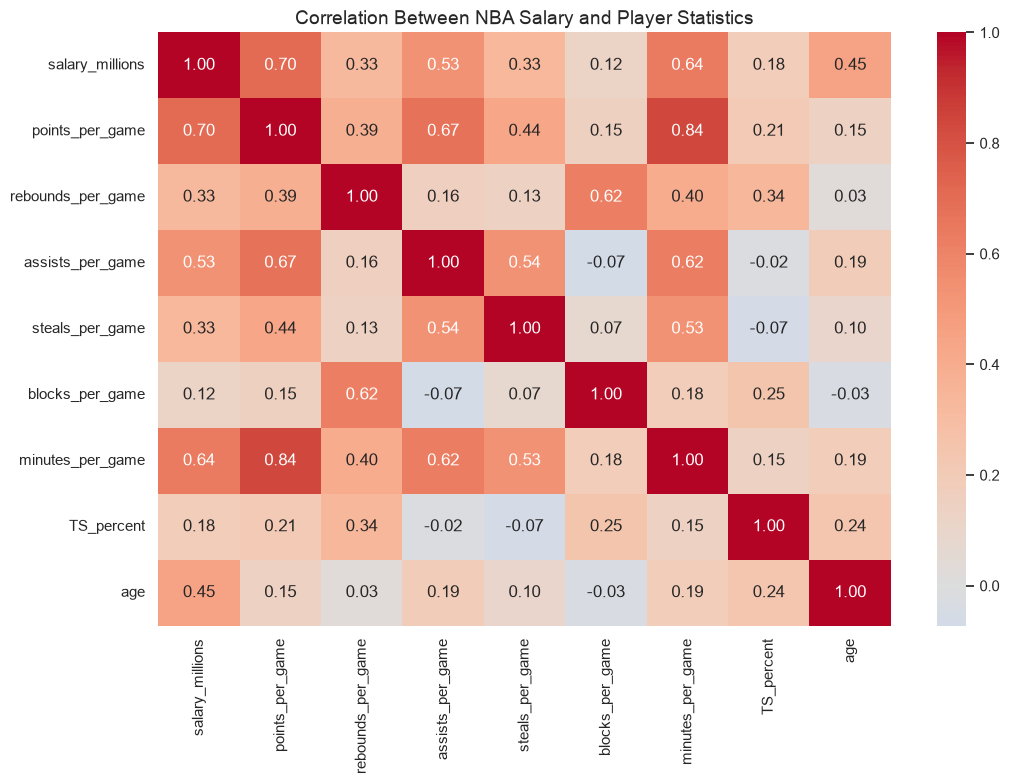

In [14]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title(
    "Correlation Between NBA Salary and Player Statistics",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [12]:
# Correlation of each statistic with salary
salary_correlations = (
    corr_matrix["salary_millions"]
    .drop("salary_millions")
    .sort_values(ascending=False)
)

print("Statistics most positively correlated with salary:")

display(salary_correlations)

Statistics most positively correlated with salary:


points_per_game      0.704666
minutes_per_game     0.639044
assists_per_game     0.533446
age                  0.449196
steals_per_game      0.334948
rebounds_per_game    0.326714
TS_percent           0.182377
blocks_per_game      0.124056
Name: salary_millions, dtype: float64

In [13]:
# Find possible low-salary, high-scoring players
value_candidates = analysis_df[
    (analysis_df["salary_millions"] < 10) &
    (analysis_df["points_per_game"] >= 15)
].copy()

value_candidates = value_candidates.sort_values(
    "points_per_game",
    ascending=False
)

display(
    value_candidates[
        [
            "player_name",
            "salary_millions",
            "points_per_game",
            "assists_per_game",
            "rebounds_per_game",
            "TS_percent"
        ]
    ]
)

,player_name,salary_millions,points_per_game,assists_per_game,rebounds_per_game,TS_percent
170,Franz Wagner,7.007092,24.2,4.7,5.7,55.823522
235,Jalen Williams,4.775760,21.6,5.1,5.3,57.327095
533,Trey Murphy III,5.159854,21.2,3.5,5.1,59.774516
19,Alperen Sengun,5.424654,19.1,4.9,10.3,54.494787
230,Jalen Johnson,4.510905,18.9,5.0,10.0,56.909480
489,Shaedon Sharpe,6.614160,18.5,2.8,4.5,55.143414
337,Keyonte George,4.084200,16.8,5.6,3.8,53.858675
376,Malik Beasley,6.000000,16.3,1.7,2.6,58.979340
234,Jalen Suggs,9.188385,16.2,3.7,4.0,53.551190
42,Bennedict Mathurin,7.245720,16.1,1.9,5.3,57.853225


## Key Findings

### 1. NBA Salary Distribution

The 270 eligible NBA players had an average salary of approximately $15.20 million and a median salary of $9.83 million during the 2024–25 season. The substantial difference between these values suggests a right-skewed salary distribution, with a smaller group of highly compensated players raising the overall average.

### 2. Relationship Between Salary and Scoring

Player salary and points per game demonstrated a strong positive correlation (r = 0.705). This suggests that players earning higher salaries generally contribute more scoring production. However, the relationship is not perfect, indicating that players earning similar salaries can provide significantly different levels of scoring output.

### 3. Salary and Scoring Efficiency

True Shooting Percentage showed a relatively weak positive correlation with salary (r ≈ 0.18). This indicates that higher salaries are not necessarily associated with greater scoring efficiency. Differences in player roles, offensive responsibilities, and shot difficulty may help explain this relationship.

### 4. Strongest Statistical Relationships

Among the variables analyzed, points per game (r = 0.705), minutes per game (r ≈ 0.64), and assists per game (r ≈ 0.53) had the strongest positive correlations with salary. These results suggest that scoring production, playing time, and playmaking are more closely associated with compensation than individual defensive box-score statistics or shooting efficiency.

### 5. Potentially Undervalued Players

The initial analysis identified several players producing substantial scoring output while earning less than $10 million annually. Notable examples include Franz Wagner, Jalen Williams, Trey Murphy III, Alperen Sengun, and Christian Braun.

These players represent interesting candidates for further investigation, although scoring alone is insufficient to determine overall player value.

### Limitations

This analysis identifies statistical relationships rather than causal effects. NBA salaries depend on contract timing, experience, collective bargaining restrictions, market conditions, and factors beyond single-season box-score production.

Additionally, the analysis excludes players with fewer than approximately 1,000 minutes played, and the salary dataset requires further validation of compensation definitions. Historical team labels also require verification.

### Next Steps

The next phase will develop a standardized player production score incorporating scoring, playmaking, rebounding, defensive box-score contributions, and scoring efficiency.

This production score will then be compared against salary-based expectations to identify players who provide above-expected statistical production relative to their compensation.

In [15]:
r = analysis_df["salary_millions"].corr(
    analysis_df["points_per_game"]
)

r_squared = r ** 2

print("Pearson correlation:", round(r, 3))
print("R-squared:", round(r_squared, 3))

Pearson correlation: 0.705
R-squared: 0.497
